<a href="https://colab.research.google.com/github/Walquiriawp/IA_Ansiedade/blob/main/EDA_e_Preprocessamento_IA_Ansiedade_(5).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizado de Máquina Aplicado à Prontidão e Ansiedade de Estudantes Frente à IA
### Notebook de Análise Exploratória e Pré-processamento

Este notebook contém o código completo da Análise Exploratória de Dados (EDA) e do pré-processamento final utilizados no estudo, com base no dataset multinacional do consórcio FITPED (Skalka et al., 2025).

**Estrutura do notebook:**
1. Configuração do ambiente e upload dos dados
2. Carga e inspeção inicial dos dados
3. Investigação de valores ausentes estruturais
4. Cálculo dos escores agregados por construto
5. Confiabilidade dos construtos (Alfa de Cronbach)
6. Estatística descritiva e visualizações
7. Análise de correlação entre construtos
8. Variação por subgrupos (país e ano)
9. Definição da variável-alvo (categorização da Ansiedade)
10. Pré-processamento final (outliers, codificação, split treino/teste)
11. Exportação dos datasets prontos para modelagem


## 1. Configuração do ambiente e upload dos dados

In [3]:
# Instalação de pacotes (geralmente já disponíveis no Colab; descomente se necessário)
# !pip install pandas numpy matplotlib seaborn scipy scikit-learn -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42


In [4]:
# Upload manual dos arquivos no Google Colab
# Execute esta célula e selecione os arquivos 'ai_literacy_data.csv' e 'dicionario_dados.csv'
from google.colab import files
uploaded = files.upload()


In [5]:
# Alternativa: montar o Google Drive (caso os arquivos já estejam salvos lá)
from google.colab import drive
drive.mount('/content/drive')
DATA_PATH = '/content/drive/MyDrive/Mestrado em informática Aplicada - UFRPE /Analise de dados e aprendizado de maquina/ai_literacy_data.csv'

#DATA_PATH = 'ai_literacy_data.csv'  # ajuste se necessário


Mounted at /content/drive


## 2. Carga e inspeção inicial dos dados

In [6]:
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')

df = df.rename(columns={
    'Grade (year of study):': 'Grade',
    'Study programme:': 'Study_programme',
    'How many hours of AI-related courses have you taken (from 0 to many, not per week, summary in your study):': 'AI_hours'
})

print("Shape:", df.shape)
df.head()


Shape: (1205, 58)


,user_id,year,Grade,Age,Gender,Country,Study_programme,AI_hours,L1,L2,L3,L4,L5,RE1,RE2,RE3,RE4,RE5,RE6,R1,R2,R3,R4,R5,R6,SG1,SG2,SG3,SG4,SG5,CM1,CM2,CM3,CM4,A1,A2,A3,A4,A5,IM1,IM2,IM3,IM4,S1,S2,S3,S4,S5,C1,C2,C3,C4,C5,BI1,BI2,BI3,BI4,BI5
0,1,2022,1,20,male,SK,IT,0,4,4,4,4,4,4,4,3,3,2,3,5,2,2,2,3,2,4,4,4,4,4,2,3,2,4,4,3,2,2,2,3,3,3,3,3,3,3,3,3,4,4,4,4,0,0,0,0,0,0
1,2,2022,3,22,male,SK,IT,25,4,4,5,2,2,4,3,4,4,2,3,4,5,5,3,4,4,4,4,4,5,4,4,4,4,4,3,4,3,4,4,5,0,3,4,4,4,5,4,3,3,4,4,4,3,3,4,5,3,3
2,3,2022,1,17,male,SK,IT,0,5,5,5,3,1,5,5,5,5,2,5,5,4,4,3,4,5,5,5,5,5,5,4,4,3,3,1,2,2,1,1,5,3,3,3,4,4,4,3,3,3,5,3,3,3,3,3,4,3,3
3,4,2022,3,22,male,SK,education,0,5,5,3,5,5,5,5,4,5,3,3,4,5,5,5,3,5,3,4,5,2,4,4,2,4,3,3,4,1,1,2,0,0,4,0,0,0,4,0,0,0,0,0,0,0,0,3,4,4,4
4,5,2022,1,20,male,SK,IT,0,5,4,4,5,3,4,4,4,3,3,4,4,4,4,2,2,4,3,3,4,4,3,3,4,4,2,2,2,2,2,2,4,4,2,3,3,3,4,3,3,4,4,3,4,2,3,4,4,4,4


In [7]:
print("=== Tipos de dados ===")
print(df.dtypes)

print("\n=== Estatísticas descritivas (numéricas) ===")
df.describe()


=== Tipos de dados ===
user_id             int64
year                int64
Grade               int64
Age                 int64
Gender             object
Country            object
Study_programme    object
AI_hours            int64
L1                  int64
L2                  int64
L3                  int64
L4                  int64
L5                  int64
RE1                 int64
RE2                 int64
RE3                 int64
RE4                 int64
RE5                 int64
RE6                 int64
R1                  int64
R2                  int64
R3                  int64
R4                  int64
R5                  int64
R6                  int64
SG1                 int64
SG2                 int64
SG3                 int64
SG4                 int64
SG5                 int64
CM1                 int64
CM2                 int64
CM3                 int64
CM4                 int64
A1                  int64
A2                  int64
A3                  int64
A4             

,user_id,year,Grade,Age,AI_hours,L1,L2,L3,L4,L5,RE1,RE2,RE3,RE4,RE5,RE6,R1,R2,R3,R4,R5,R6,SG1,SG2,SG3,SG4,SG5,CM1,CM2,CM3,CM4,A1,A2,A3,A4,A5,IM1,IM2,IM3,IM4,S1,S2,S3,S4,S5,C1,C2,C3,C4,C5,BI1,BI2,BI3,BI4,BI5
count,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.000000,1205.00000,1205.000000,1205.000000
mean,552.048963,2023.019087,2.385062,22.808299,15.804979,4.558506,4.529461,3.953527,3.229876,3.683817,4.310373,4.310373,3.854772,3.877178,3.204979,3.401660,4.278838,3.929461,4.077178,3.547718,3.346888,3.603320,3.924481,3.765145,3.821577,3.594191,3.770124,4.048133,3.687137,3.393361,3.533610,2.857261,2.917842,2.364315,2.405809,2.337759,2.988382,2.434855,2.585062,2.048133,2.580083,2.038174,3.102905,1.966805,2.175934,2.317012,2.855602,2.408299,2.886307,2.121992,2.571784,3.003320,3.40332,3.414108,3.473029
std,336.806184,0.952598,1.181717,5.403389,55.350583,0.727443,0.717718,1.017863,1.360735,1.093067,0.783934,0.760268,1.046901,0.942633,1.066856,0.999001,0.852157,0.908160,0.886322,1.042497,0.997089,1.019082,0.990037,1.081610,0.919807,1.008502,0.876665,0.889776,1.048274,1.162662,1.035054,1.107753,1.087862,1.111352,1.170143,1.204067,1.790487,1.738306,1.818722,1.857732,1.752910,1.895581,1.765590,1.840092,1.737963,1.769270,1.893965,1.752340,1.843869,1.770717,1.779600,1.572708,1.56211,1.579131,1.548328
min,1.000000,2022.000000,1.000000,17.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,249.000000,2022.000000,2.000000,20.000000,0.000000,4.000000,4.000000,3.000000,2.000000,3.000000,4.000000,4.000000,3.000000,3.000000,3.000000,3.000000,4.000000,3.000000,4.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,3.000000,3.000000,3.000000,2.000000,2.000000,2.000000,1.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,3.00000,3.000000,3.000000
50%,544.000000,2023.000000,2.000000,21.000000,0.000000,5.000000,5.000000,4.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,3.000000,2.000000,2.000000,2.000000,4.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,3.000000,3.000000,3.000000,4.000000,3.000000,4.000000,3.000000,3.000000,3.000000,4.00000,4.000000,4.000000
75%,845.000000,2024.000000,3.000000,23.000000,5.000000,5.000000,5.000000,5.000000,4.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.000000,4.000000,5.000000,5.000000,5.000000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.00000,4.000000,5.000000
max,1147.000000,2024.000000,7.000000,56.000000,1000.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.0

In [8]:
print("user_id duplicados:", df['user_id'].duplicated().sum())
print("Linhas totais:", len(df))
print("user_id únicos:", df['user_id'].nunique())

print("\n=== Distribuição por ano ===")
print(df['year'].value_counts().sort_index())

print("\n=== Distribuição por país ===")
print(df['Country'].value_counts())

print("\n=== Distribuição por gênero ===")
print(df['Gender'].value_counts())

print("\n=== Distribuição por curso ===")
print(df['Study_programme'].value_counts())


user_id duplicados: 59
Linhas totais: 1205
user_id únicos: 1146

=== Distribuição por ano ===
year
2022    535
2023    112
2024    558
Name: count, dtype: int64

=== Distribuição por país ===
Country
SK    686
PL    299
CZ    106
ID     65
LT     38
TR      6
FR      3
UA      2
Name: count, dtype: int64

=== Distribuição por gênero ===
Gender
male      793
female    402
other      10
Name: count, dtype: int64

=== Distribuição por curso ===
Study_programme
IT                832
education         188
other              68
management         52
language           28
IT education       22
STEM education     14
it                  1
Name: count, dtype: int64


## 3. Investigação de valores ausentes estruturais

Os construtos **IM, S, C e BI** utilizam escala 0-5 (diferente dos demais, que vão de 1-5). A hipótese testada é que "0" nesses construtos representa uma resposta "não aplicável" (ausência estrutural), e não um ponto real da escala.

In [9]:
constructs = {
    'L': ['L1','L2','L3','L4','L5'],
    'RE': ['RE1','RE2','RE3','RE4','RE5','RE6'],
    'R': ['R1','R2','R3','R4','R5','R6'],
    'SG': ['SG1','SG2','SG3','SG4','SG5'],
    'CM': ['CM1','CM2','CM3','CM4'],
    'A': ['A1','A2','A3','A4','A5'],
    'IM': ['IM1','IM2','IM3','IM4'],
    'S': ['S1','S2','S3','S4','S5'],
    'C': ['C1','C2','C3','C4','C5'],
    'BI': ['BI1','BI2','BI3','BI4','BI5'],
}
structural_na_constructs = ['IM', 'S', 'C', 'BI']

print("=== Proporção de zeros por item ===")
for name, items in constructs.items():
    for it in items:
        pct_zero = (df[it] == 0).mean() * 100
        print(f"{it}: {pct_zero:.1f}% zeros")
    print()


=== Proporção de zeros por item ===
L1: 0.0% zeros
L2: 0.0% zeros
L3: 0.0% zeros
L4: 0.0% zeros
L5: 0.0% zeros

RE1: 0.0% zeros
RE2: 0.0% zeros
RE3: 0.0% zeros
RE4: 0.0% zeros
RE5: 0.0% zeros
RE6: 0.0% zeros

R1: 0.0% zeros
R2: 0.0% zeros
R3: 0.0% zeros
R4: 0.0% zeros
R5: 0.0% zeros
R6: 0.0% zeros

SG1: 0.0% zeros
SG2: 0.0% zeros
SG3: 0.0% zeros
SG4: 0.0% zeros
SG5: 0.0% zeros

CM1: 0.0% zeros
CM2: 0.0% zeros
CM3: 0.0% zeros
CM4: 0.0% zeros

A1: 0.0% zeros
A2: 0.0% zeros
A3: 0.0% zeros
A4: 0.0% zeros
A5: 0.0% zeros

IM1: 21.3% zeros
IM2: 26.6% zeros
IM3: 27.2% zeros
IM4: 40.9% zeros

S1: 26.1% zeros
S2: 42.6% zeros
S3: 20.4% zeros
S4: 42.8% zeros
S5: 33.2% zeros

C1: 32.0% zeros
C2: 27.6% zeros
C3: 28.9% zeros
C4: 25.8% zeros
C5: 35.0% zeros

BI1: 26.9% zeros
BI2: 14.8% zeros
BI3: 12.9% zeros
BI4: 12.8% zeros
BI5: 12.0% zeros



In [10]:
print("=== Respondentes com bloco inteiro zerado (indicativo de 'pulou' o bloco) ===")
for name in structural_na_constructs:
    items = constructs[name]
    all_zero = (df[items] == 0).all(axis=1).sum()
    print(f"{name}: {all_zero} respondentes ({all_zero/len(df)*100:.1f}%)")


=== Respondentes com bloco inteiro zerado (indicativo de 'pulou' o bloco) ===
IM: 183 respondentes (15.2%)
S: 194 respondentes (16.1%)
C: 267 respondentes (22.2%)
BI: 105 respondentes (8.7%)


In [11]:
# Confirmação: quem zera o bloco IM tem muito menos horas de curso de IA?
im_zero = (df[constructs['IM']] == 0).all(axis=1)
print(df.groupby(im_zero)['AI_hours'].describe())


        count       mean        std  min  25%  50%   75%     max
False  1022.0  18.156556  59.560905  0.0  0.0  0.0  10.0  1000.0
True    183.0   2.672131  12.724107  0.0  0.0  0.0   0.0   100.0


## 4. Cálculo dos escores agregados por construto

Para os construtos com missing estrutural (IM, S, C, BI), os valores 0 são recodificados como ausentes (NaN) antes do cálculo da média.

In [12]:
scores = pd.DataFrame({'user_id': df['user_id']})

for name, items in constructs.items():
    if name in structural_na_constructs:
        tmp = df[items].replace(0, np.nan)
        scores[name] = tmp.mean(axis=1)
        scores[f'{name}_na'] = tmp.isna().all(axis=1).astype(int)  # flag de ausência estrutural
    else:
        scores[name] = df[items].mean(axis=1)

scores.head()


,user_id,L,RE,R,SG,CM,A,IM,IM_na,S,S_na,C,C_na,BI,BI_na
0,1,4.0,3.166667,2.666667,4.0,2.75,2.6,3.00,0,3.0,0,4.0,0,NaN,1
1,2,3.4,3.333333,4.166667,4.2,4.00,3.6,4.00,0,4.0,0,3.6,0,3.60,0
2,3,3.8,4.500000,4.166667,5.0,3.50,1.4,3.50,0,3.6,0,3.4,0,3.20,0
3,4,4.6,4.166667,4.500000,3.6,3.25,2.2,4.00,0,4.0,0,NaN,1,3.75,0
4,5,4.2,3.666667,3.333333,3.4,3.25,2.0,3.25,0,3.2,0,3.4,0,3.80,0


## 5. Confiabilidade dos construtos (Alfa de Cronbach)

In [13]:
def cronbach_alpha(items_df):
    items_df = items_df.dropna()
    k = items_df.shape[1]
    item_var = items_df.var(axis=0, ddof=1).sum()
    total_var = items_df.sum(axis=1).var(ddof=1)
    return (k / (k - 1)) * (1 - item_var / total_var)

print("=== Alfa de Cronbach por construto ===")
for name, items in constructs.items():
    sub = df[items].replace(0, np.nan) if name in structural_na_constructs else df[items]
    alpha = cronbach_alpha(sub)
    print(f"{name}: alpha = {alpha:.3f}  (N itens = {len(items)})")


=== Alfa de Cronbach por construto ===
L: alpha = 0.688  (N itens = 5)
RE: alpha = 0.825  (N itens = 6)
R: alpha = 0.828  (N itens = 6)
SG: alpha = 0.736  (N itens = 5)
CM: alpha = 0.848  (N itens = 4)
A: alpha = 0.882  (N itens = 5)
IM: alpha = 0.832  (N itens = 4)
S: alpha = 0.881  (N itens = 5)
C: alpha = 0.865  (N itens = 5)
BI: alpha = 0.878  (N itens = 5)


## 6. Estatística descritiva e visualizações

In [14]:
desc = scores.drop(columns=['user_id'] + [c for c in scores.columns if c.endswith('_na')]).describe().T
desc['missing_%'] = scores.drop(columns=['user_id'] + [c for c in scores.columns if c.endswith('_na')]).isna().mean() * 100
desc[['count','mean','std','min','25%','50%','75%','max','missing_%']].round(2)


,count,mean,std,min,25%,50%,75%,max,missing_%
L,1205.0,3.99,0.68,1.0,3.60,4.00,4.40,5.0,0.00
RE,1205.0,3.83,0.69,1.0,3.50,3.83,4.33,5.0,0.00
R,1205.0,3.80,0.70,1.0,3.50,3.83,4.33,5.0,0.00
SG,1205.0,3.78,0.68,1.0,3.40,3.80,4.20,5.0,0.00
CM,1205.0,3.67,0.86,1.0,3.25,3.75,4.25,5.0,0.00
A,1205.0,2.58,0.94,1.0,2.00,2.40,3.20,5.0,0.00
IM,1022.0,3.56,0.87,1.0,3.00,3.67,4.00,5.0,15.19
S,1011.0,3.58,0.82,1.0,3.00,3.67,4.00,5.0,16.10
C,938.0,3.60,0.75,1.0,3.00,3.60,4.00,5.0,22.16
BI,1100.0,3.77,0.79,1.0,3.40,4.00,4.20,5.0,8.71


/tmp/ipykernel_7963/1642776603.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=melted, x='Construto', y='Escore', order=order, ax=ax, palette='viridis')


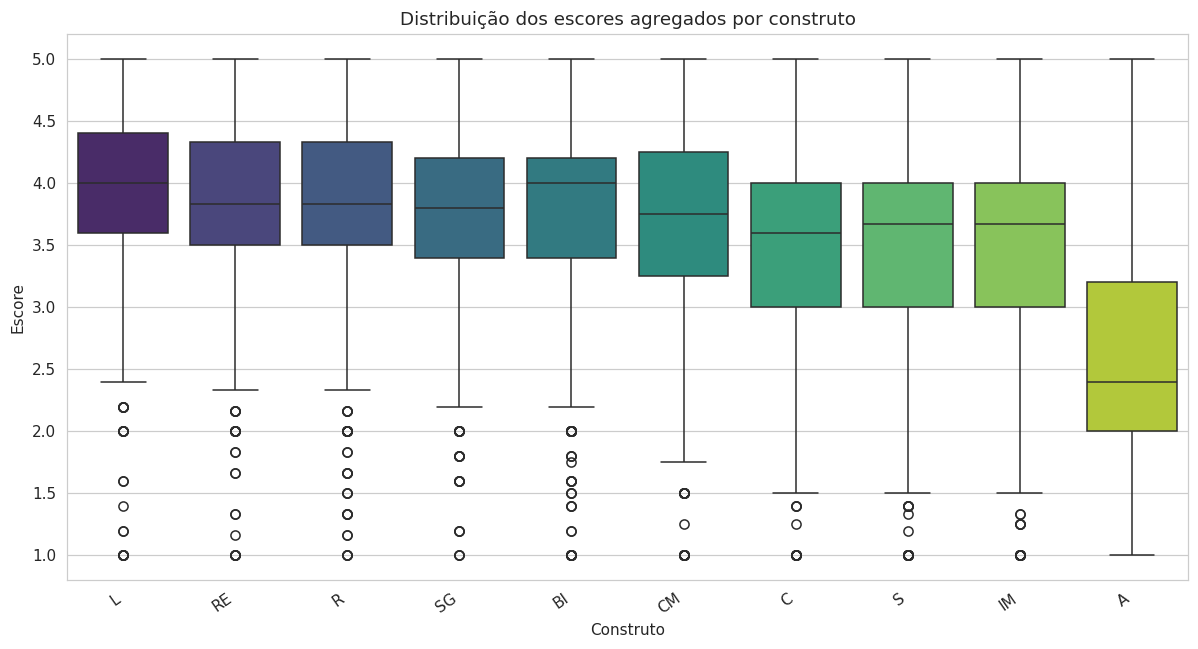

In [15]:
# Boxplot dos escores por construto
construct_cols = list(constructs.keys())
fig, ax = plt.subplots(figsize=(11, 6))
melted = scores[construct_cols].melt(var_name='Construto', value_name='Escore')
order = scores[construct_cols].mean().sort_values(ascending=False).index
sns.boxplot(data=melted, x='Construto', y='Escore', order=order, ax=ax, palette='viridis')
ax.set_title('Distribuição dos escores agregados por construto')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()


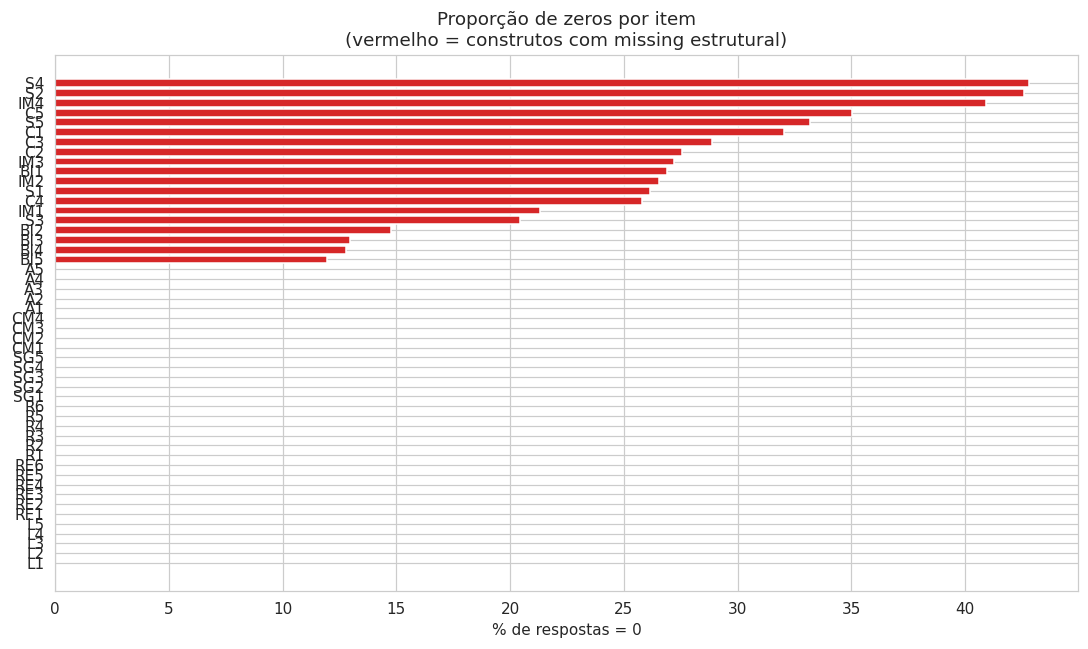

In [16]:
# Proporção de zeros por item (missingness)
zero_pct = {}
for name, items in constructs.items():
    for it in items:
        zero_pct[it] = (df[it] == 0).mean() * 100
s = pd.Series(zero_pct).sort_values(ascending=True)
colors = ['#d62728' if v > 10 else '#1f77b4' for v in s.values]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(s.index, s.values, color=colors)
ax.set_xlabel('% de respostas = 0')
ax.set_title('Proporção de zeros por item\n(vermelho = construtos com missing estrutural)')
plt.tight_layout()
plt.show()


## 7. Análise de correlação entre construtos

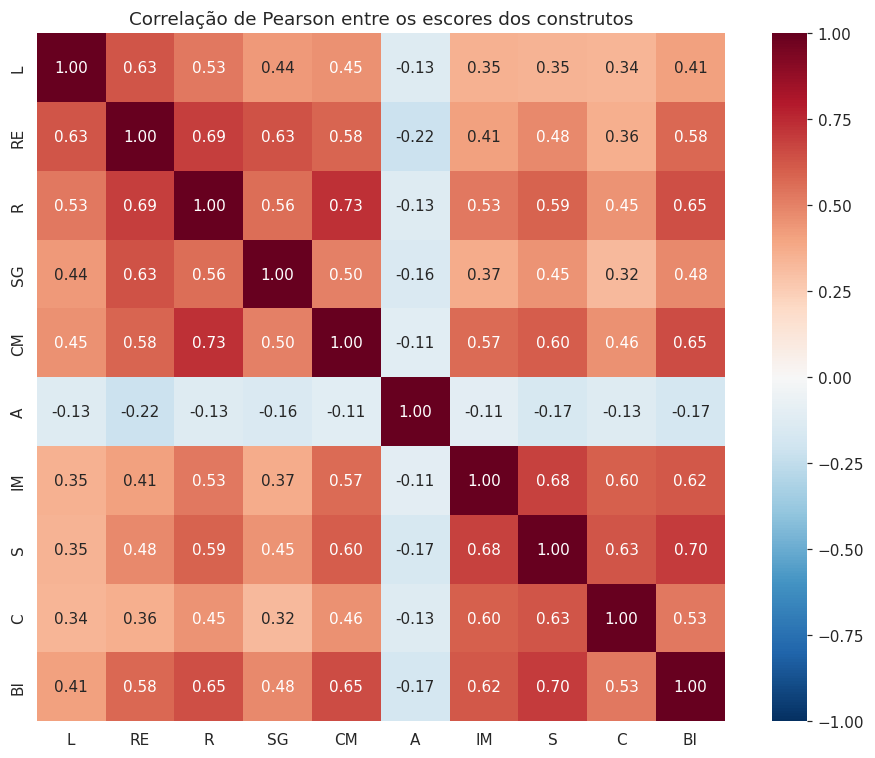

In [17]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = scores[construct_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title('Correlação de Pearson entre os escores dos construtos')
plt.tight_layout()
plt.show()


## 8. Variação por subgrupos (país e ano)

/tmp/ipykernel_7963/4063370541.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=scores, x='Country', y='A', order=order_c, ax=ax, palette='mako')


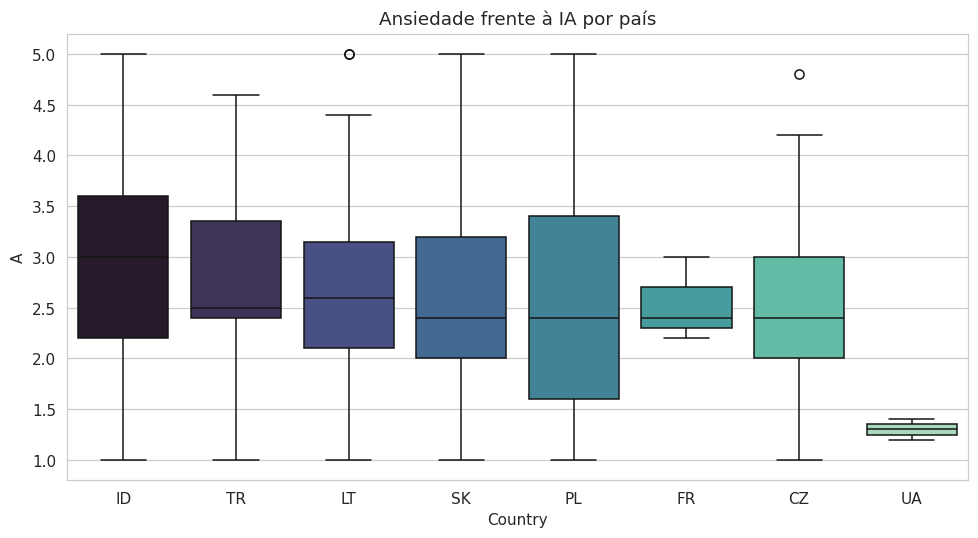

In [18]:
scores['Country'] = df['Country'].values
scores['year'] = df['year'].values

fig, ax = plt.subplots(figsize=(9, 5))
order_c = scores.groupby('Country')['A'].mean().sort_values(ascending=False).index
sns.boxplot(data=scores, x='Country', y='A', order=order_c, ax=ax, palette='mako')
ax.set_title('Ansiedade frente à IA por país')
plt.tight_layout()
plt.show()


/tmp/ipykernel_7963/1810801320.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=scores, x='year', y='A', ax=ax, palette='flare')


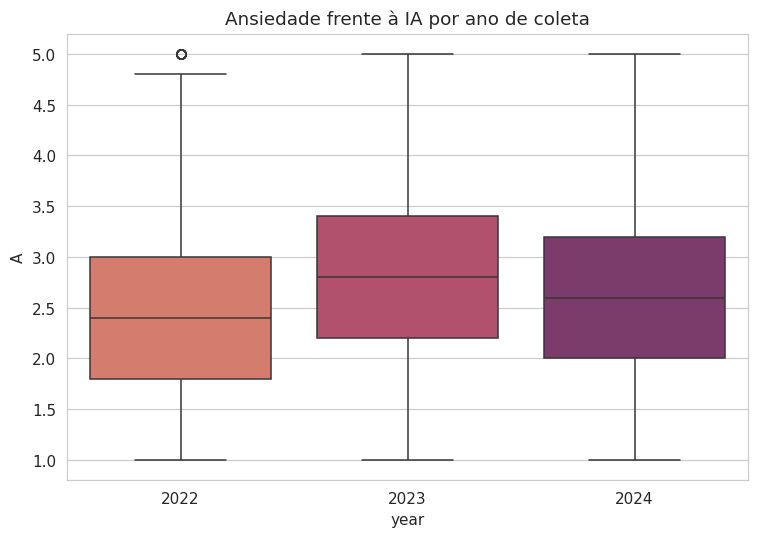

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=scores, x='year', y='A', ax=ax, palette='flare')
ax.set_title('Ansiedade frente à IA por ano de coleta')
plt.tight_layout()
plt.show()


## 9. Definição da variável-alvo (categorização da Ansiedade)

A variável-alvo é categorizada em três classes (Baixa / Média / Alta) com base nos **tercis** da distribuição do escore de Ansiedade, estratégia escolhida por gerar classes mais balanceadas do que cortes fixos teóricos, além de ser mais adequada a uma distribuição não-normal (testada abaixo).

In [20]:
print("Assimetria (skewness):", stats.skew(scores['A']))
print("Shapiro-Wilk p-value:", stats.shapiro(scores['A'].sample(min(500, len(scores)), random_state=RANDOM_STATE))[1])


Assimetria (skewness): 0.4326902221482091
Shapiro-Wilk p-value: 6.786347249457013e-08


In [21]:
t1, t2 = scores['A'].quantile([1/3, 2/3])
print(f"Corte T1 (Baixa/Média): {t1:.3f}")
print(f"Corte T2 (Média/Alta): {t2:.3f}")

def classify(x):
    if x <= t1:
        return 'Baixa'
    elif x <= t2:
        return 'Média'
    else:
        return 'Alta'

scores['Anxiety_class'] = scores['A'].apply(classify)

print("\nDistribuição das classes:")
print(scores['Anxiety_class'].value_counts())
print(scores['Anxiety_class'].value_counts(normalize=True).round(3) * 100)


Corte T1 (Baixa/Média): 2.000
Corte T2 (Média/Alta): 3.000

Distribuição das classes:
Anxiety_class
Média    460
Baixa    413
Alta     332
Name: count, dtype: int64
Anxiety_class
Média    38.2
Baixa    34.3
Alta     27.6
Name: proportion, dtype: float64


## 10. Pré-processamento final

In [22]:
# Variáveis contextuais
scores['Age'] = df['Age'].values
scores['Grade'] = df['Grade'].values
scores['AI_hours'] = df['AI_hours'].values
scores['Gender'] = df['Gender'].values
scores['Study_programme'] = df['Study_programme'].str.strip().str.lower().values

# Tratamento de outliers
scores['Age_capped'] = scores['Age'].clip(upper=45)
scores['AI_hours_log'] = np.log1p(scores['AI_hours'].clip(upper=300))

# Agrupar países com amostra muito pequena (N <= 6) em 'Other_small'
small_countries = ['TR', 'FR', 'UA']
scores['Country_grp'] = scores['Country'].apply(lambda c: 'Other_small' if c in small_countries else c)


In [23]:
# Split treino/teste SEM vazamento entre registros do mesmo estudante (59 longitudinais)
rep_class = scores.groupby('user_id')['Anxiety_class'].agg(lambda x: x.mode().iloc[0])
unique_users = rep_class.index.values
y_strat = rep_class.values

train_users, test_users = train_test_split(
    unique_users, test_size=0.2, random_state=RANDOM_STATE, stratify=y_strat
)

scores['split'] = np.where(scores['user_id'].isin(train_users), 'train', 'test')

print(scores['split'].value_counts())
print()
print(pd.crosstab(scores['split'], scores['Anxiety_class'], normalize='index').round(3))


split
train    969
test     236
Name: count, dtype: int64

Anxiety_class   Alta  Baixa  Média
split                             
test           0.275  0.347  0.377
train          0.276  0.342  0.383


In [24]:
# Codificação one-hot das categóricas
cat_cols = ['Gender', 'Country_grp', 'Study_programme']
scores_encoded = pd.get_dummies(scores, columns=cat_cols, drop_first=False)

predictor_constructs = ['L', 'RE', 'R', 'SG', 'CM', 'IM', 'S', 'C', 'BI']  # exclui 'A' (usado só p/ gerar o alvo)
na_flags = ['IM_na', 'S_na', 'C_na', 'BI_na']
numeric_context = ['Age_capped', 'Grade', 'AI_hours_log']
dummy_cols = [c for c in scores_encoded.columns if c.startswith(('Gender_', 'Country_grp_', 'Study_programme_'))]

feature_cols = predictor_constructs + na_flags + numeric_context + dummy_cols
print(f"Total de features: {len(feature_cols)}")
print(feature_cols)


Total de features: 32
['L', 'RE', 'R', 'SG', 'CM', 'IM', 'S', 'C', 'BI', 'IM_na', 'S_na', 'C_na', 'BI_na', 'Age_capped', 'Grade', 'AI_hours_log', 'Gender_female', 'Gender_male', 'Gender_other', 'Country_grp_CZ', 'Country_grp_ID', 'Country_grp_LT', 'Country_grp_Other_small', 'Country_grp_PL', 'Country_grp_SK', 'Study_programme_education', 'Study_programme_it', 'Study_programme_it education', 'Study_programme_language', 'Study_programme_management', 'Study_programme_other', 'Study_programme_stem education']


In [25]:
# Versão A: imputação (p/ Regressão Logística, k-NN, SVM)
df_model_impute = scores_encoded[['user_id', 'split', 'Anxiety_class'] + feature_cols].copy()
train_mask = df_model_impute['split'] == 'train'

for col in predictor_constructs:
    med = df_model_impute.loc[train_mask, col].median()
    df_model_impute[col] = df_model_impute[col].fillna(med)

num_cols_to_scale = predictor_constructs + numeric_context
scaler = StandardScaler()
scaler.fit(df_model_impute.loc[train_mask, num_cols_to_scale])

df_model_scaled = df_model_impute.copy()
df_model_scaled[num_cols_to_scale] = scaler.transform(df_model_impute[num_cols_to_scale])

print("NaNs restantes (deve ser 0):", df_model_scaled[feature_cols].isna().sum().sum())


NaNs restantes (deve ser 0): 0


In [26]:
# Versão B: missing nativo preservado (p/ XGBoost)
df_model_native = scores_encoded[['user_id', 'split', 'Anxiety_class'] + feature_cols].copy()

print("NaNs preservados por construto:")
print(df_model_native[predictor_constructs].isna().sum())


NaNs preservados por construto:
L       0
RE      0
R       0
SG      0
CM      0
IM    183
S     194
C     267
BI    105
dtype: int64


## 11. Exportação dos datasets prontos para modelagem

In [27]:
df_model_scaled.to_csv('dataset_modelagem_imputado_padronizado.csv', index=False)
df_model_native.to_csv('dataset_modelagem_missing_nativo.csv', index=False)
scores.to_csv('escores_completos_com_flags.csv', index=False)

print("Arquivos exportados com sucesso.")


Arquivos exportados com sucesso.


In [28]:
# No Colab, baixe os arquivos gerados para seu computador:
from google.colab import files
files.download('dataset_modelagem_imputado_padronizado.csv')
files.download('dataset_modelagem_missing_nativo.csv')
files.download('escores_completos_com_flags.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Próximos passos

Com os datasets `dataset_modelagem_imputado_padronizado.csv` (para Regressão Logística, k-NN, SVM) e `dataset_modelagem_missing_nativo.csv` (para XGBoost) prontos, a próxima etapa do estudo é o treinamento e a comparação dos algoritmos de classificação supervisionada, seguida da aplicação do SHAP para interpretabilidade e, posteriormente, a clusterização K-Means para identificação de perfis latentes de estudantes.

---
## 12. Treinamento dos modelos supervisionados

Nesta etapa, os quatro algoritmos definidos no desenho metodológico (Regressão Logística, Random Forest, XGBoost e k-NN) são treinados para a tarefa de classificação da Ansiedade em três classes (Baixa, Média, Alta). O XGBoost utiliza a versão do dataset com valores ausentes nativos; os demais algoritmos utilizam a versão imputada e padronizada.

In [29]:
# !pip install shap xgboost -q

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
import shap


In [30]:
# Codificação da variável-alvo (string -> inteiro), necessária para XGBoost e para métricas
le = LabelEncoder()
y_all = le.fit_transform(scores['Anxiety_class'])  # ou df_model_scaled['Anxiety_class'], mesma ordem de linhas
print("Classes codificadas:", dict(zip(le.classes_, le.transform(le.classes_))))


Classes codificadas: {'Alta': np.int64(0), 'Baixa': np.int64(1), 'Média': np.int64(2)}


In [31]:
feature_cols = [c for c in df_model_scaled.columns if c not in ['user_id', 'split', 'Anxiety_class']]

# ---- Conjunto IMPUTADO/PADRONIZADO (Regressão Logística, k-NN) ----
X_train_imp = df_model_scaled.loc[df_model_scaled['split']=='train', feature_cols]
X_test_imp  = df_model_scaled.loc[df_model_scaled['split']=='test',  feature_cols]
y_train = le.transform(df_model_scaled.loc[df_model_scaled['split']=='train', 'Anxiety_class'])
y_test  = le.transform(df_model_scaled.loc[df_model_scaled['split']=='test',  'Anxiety_class'])

# ---- Conjunto com MISSING NATIVO (XGBoost, Random Forest) ----
X_train_nat = df_model_native.loc[df_model_native['split']=='train', feature_cols]
X_test_nat  = df_model_native.loc[df_model_native['split']=='test',  feature_cols]

print("Treino:", X_train_imp.shape, "| Teste:", X_test_imp.shape)


Treino: (969, 32) | Teste: (236, 32)


In [32]:
models = {}

# 1) Regressão Logística (baseline linear)
models['Regressão Logística'] = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)  # 'multinomial' é o padrão do solver lbfgs em versões recentes do sklearn
models['Regressão Logística'].fit(X_train_imp, y_train)

# 2) k-NN
models['k-NN'] = KNeighborsClassifier(n_neighbors=15)
models['k-NN'].fit(X_train_imp, y_train)

# 2.5) SVM (kernel RBF) - comparação direta com o estado da arte da literatura de ansiedade (Daza et al., 2023)
models['SVM'] = SVC(kernel='rbf', C=1.0, probability=True, random_state=RANDOM_STATE)
models['SVM'].fit(X_train_imp, y_train)

# 3) Random Forest (usa versão nativa; RF do sklearn não aceita NaN, então aqui usamos a imputada)
models['Random Forest'] = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE)
models['Random Forest'].fit(X_train_imp, y_train)

# 4) XGBoost (trata NaN nativamente -> usa o dataset com missing preservado)
models['XGBoost'] = xgb.XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    objective='multi:softprob', num_class=3,
    random_state=RANDOM_STATE, eval_metric='mlogloss'
)
models['XGBoost'].fit(X_train_nat, y_train)

print("Modelos treinados:", list(models.keys()))


Modelos treinados: ['Regressão Logística', 'k-NN', 'SVM', 'Random Forest', 'XGBoost']


### 12.1 Validação cruzada estratificada por grupo (k=5) e teste de Wilcoxon

Como 59 estudantes responderam ao instrumento em mais de uma onda de coleta, a validação cruzada utiliza o `StratifiedGroupKFold`, que garante que todos os registros de um mesmo estudante permaneçam sempre no mesmo fold (evitando vazamento de dados) e mantém a proporção das classes em cada fold. A validação é feita **apenas sobre o conjunto de treino**, preservando o conjunto de teste como avaliação final e independente.

In [33]:
from sklearn.model_selection import StratifiedGroupKFold
from scipy.stats import wilcoxon

groups_train = df_model_scaled.loc[df_model_scaled['split']=='train', 'user_id'].reset_index(drop=True)
X_train_imp_cv = X_train_imp.reset_index(drop=True)
X_train_nat_cv = X_train_nat.reset_index(drop=True)
y_train_cv = y_train.copy()

model_builders = {
    'Regressão Logística': lambda: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'k-NN': lambda: KNeighborsClassifier(n_neighbors=15),
    'SVM': lambda: SVC(kernel='rbf', C=1.0, probability=True, random_state=RANDOM_STATE),
    'Random Forest': lambda: RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE),
    'XGBoost': lambda: xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
                                          objective='multi:softprob', num_class=3,
                                          random_state=RANDOM_STATE, eval_metric='mlogloss'),
}
uses_native = {'XGBoost'}  # algoritmos que usam o dataset com missing nativo

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {name: [] for name in model_builders}

for fold_i, (tr_idx, val_idx) in enumerate(cv.split(X_train_imp_cv, y_train_cv, groups=groups_train)):
    for name, builder in model_builders.items():
        Xsrc = X_train_nat_cv if name in uses_native else X_train_imp_cv
        model = builder()
        model.fit(Xsrc.iloc[tr_idx], y_train_cv[tr_idx])
        pred = model.predict(Xsrc.iloc[val_idx])
        cv_scores[name].append(f1_score(y_train_cv[val_idx], pred, average='macro'))
    print(f"Fold {fold_i+1}/5 concluído")

cv_df = pd.DataFrame(cv_scores)
cv_df


Fold 1/5 concluído
Fold 2/5 concluído
Fold 3/5 concluído
Fold 4/5 concluído
Fold 5/5 concluído


,Regressão Logística,k-NN,SVM,Random Forest,XGBoost
0,0.374016,0.370979,0.379036,0.400016,0.397613
1,0.378087,0.427784,0.391655,0.400239,0.362675
2,0.352653,0.308792,0.355595,0.345649,0.340988
3,0.472011,0.425172,0.428287,0.442375,0.457010
4,0.422494,0.400709,0.412958,0.446398,0.431568


In [34]:
# Resumo da validação cruzada (média +/- desvio-padrão do F1-macro entre os 5 folds)
cv_summary = cv_df.agg(['mean', 'std']).T.sort_values('mean', ascending=False)
cv_summary.columns = ['F1-macro (média)', 'F1-macro (DP)']
cv_summary


,F1-macro (média),F1-macro (DP)
Random Forest,0.406935,0.040811
Regressão Logística,0.399852,0.047667
XGBoost,0.397971,0.047716
SVM,0.393506,0.028452
k-NN,0.386687,0.049196


In [35]:
# Teste de Wilcoxon (pareado por fold): melhor modelo da CV vs. os demais
best_model_cv = cv_summary.index[0]
print(f"Melhor modelo na validação cruzada: {best_model_cv}\n")

for name in model_builders:
    if name == best_model_cv:
        continue
    stat, p = wilcoxon(cv_df[best_model_cv], cv_df[name])
    sig = 'diferença estatisticamente significativa (p<0.05)' if p < 0.05 else 'sem diferença estatisticamente significativa'
    print(f"{best_model_cv} vs {name}: estatística={stat:.3f}, p-valor={p:.4f} -> {sig}")


Melhor modelo na validação cruzada: Random Forest

Random Forest vs Regressão Logística: estatística=6.000, p-valor=0.8125 -> sem diferença estatisticamente significativa
Random Forest vs k-NN: estatística=2.000, p-valor=0.1875 -> sem diferença estatisticamente significativa
Random Forest vs SVM: estatística=2.000, p-valor=0.1875 -> sem diferença estatisticamente significativa
Random Forest vs XGBoost: estatística=3.000, p-valor=0.3125 -> sem diferença estatisticamente significativa


**Nota sobre interpretação:** com apenas 5 folds, o teste de Wilcoxon tem baixo poder estatístico para detectar diferenças pequenas entre modelos (o p-valor mínimo possível já é limitado pelo número de pares). Caso nenhuma diferença seja significativa, isso deve ser reportado com transparência no artigo — indicando que os algoritmos têm desempenho estatisticamente equivalente nesta base de dados, e a escolha do "melhor modelo" para fins de interpretabilidade (SHAP) passa a ser justificada também pela sua simplicidade e velocidade.

In [36]:
# Avaliação comparativa (acurácia e F1-macro, conforme desenho metodológico)
results = []
for name, model in models.items():
    # XGBoost usa o conjunto com missing nativo; os demais (incl. SVM) usam o conjunto imputado/padronizado
    X_te = X_test_nat if name == 'XGBoost' else X_test_imp
    y_pred = model.predict(X_te)
    results.append({
        'Modelo': name,
        'Acurácia': accuracy_score(y_test, y_pred),
        'F1-macro': f1_score(y_test, y_pred, average='macro')
    })

results_df = pd.DataFrame(results).sort_values('F1-macro', ascending=False)
results_df


,Modelo,Acurácia,F1-macro
3,Random Forest,0.512712,0.502165
4,XGBoost,0.474576,0.465825
2,SVM,0.470339,0.458098
1,k-NN,0.427966,0.411454
0,Regressão Logística,0.398305,0.387399


Melhor modelo: Random Forest

              precision    recall  f1-score   support

        Alta       0.59      0.35      0.44        65
       Baixa       0.55      0.51      0.53        82
       Média       0.47      0.63      0.54        89

    accuracy                           0.51       236
   macro avg       0.53      0.50      0.50       236
weighted avg       0.53      0.51      0.51       236



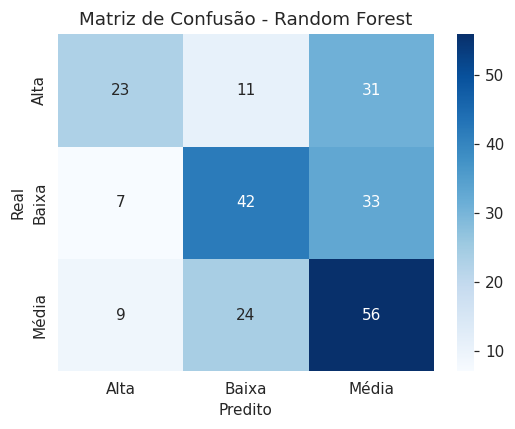

In [37]:
# Matriz de confusão do melhor modelo (ajuste o nome conforme o resultado acima)
best_model_name = results_df.iloc[0]['Modelo']
best_model = models[best_model_name]
X_te_best = X_test_nat if best_model_name == 'XGBoost' else X_test_imp

y_pred_best = best_model.predict(X_te_best)
print(f"Melhor modelo: {best_model_name}\n")
print(classification_report(y_test, y_pred_best, target_names=le.classes_))

cm = confusion_matrix(y_test, y_pred_best)
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
ax.set_xlabel('Predito'); ax.set_ylabel('Real')
ax.set_title(f'Matriz de Confusão - {best_model_name}')
plt.tight_layout()
plt.show()


### 12.2 Curvas ROC (one-vs-rest)

Como a tarefa é de classificação multiclasse (3 classes), as curvas ROC são calculadas pela estratégia *one-vs-rest*: cada classe é tratada como "positiva" contra as demais combinadas, gerando uma curva e uma AUC por classe (Hastie; Tibshirani; Friedman, 2009).

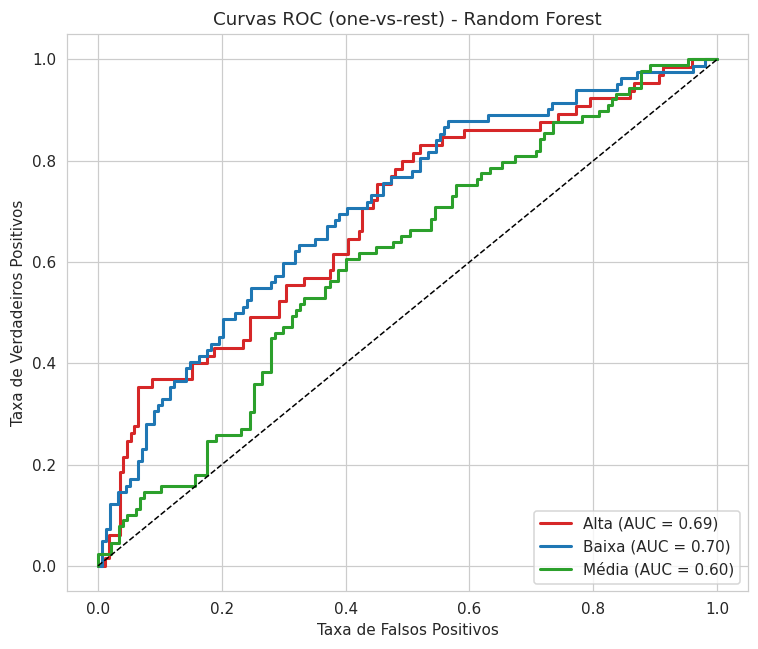

In [38]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_score_best = best_model.predict_proba(X_te_best)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

fpr, tpr, roc_auc = {}, {}, {}
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score_best[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

fig, ax = plt.subplots(figsize=(7, 6))
colors = ['#d62728', '#1f77b4', '#2ca02c']
for i, color in zip(range(n_classes), colors):
    ax.plot(fpr[i], tpr[i], color=color, lw=2, label=f'{le.classes_[i]} (AUC = {roc_auc[i]:.2f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('Taxa de Falsos Positivos')
ax.set_ylabel('Taxa de Verdadeiros Positivos')
ax.set_title(f'Curvas ROC (one-vs-rest) - {best_model_name}')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


### 12.3 Avaliação de generalização por subgrupo (país e curso)

Dado o desbalanceamento amostral identificado na EDA (56,9% da amostra na Eslováquia; 69,0% em cursos de TI), o desempenho do melhor modelo é reavaliado separadamente por país e por área de formação, a fim de verificar se a boa performance geral se mantém nos subgrupos minoritários ou se reflete principalmente o ajuste ao grupo majoritário (Objetivo Específico 5).

In [39]:
# Metadados de país/curso para os estudantes do conjunto de teste
test_meta = df_model_scaled.loc[df_model_scaled['split']=='test', ['user_id']].reset_index(drop=True).merge(
    scores[['user_id', 'Country_grp', 'Study_programme']].drop_duplicates('user_id'),
    on='user_id', how='left'
)

y_pred_best_arr = np.asarray(y_pred_best)
y_test_arr = np.asarray(y_test)


In [40]:
# Desempenho geral (referência) vs. por país
print(f"Desempenho GERAL -> Acurácia: {accuracy_score(y_test_arr, y_pred_best_arr):.3f} | F1-macro: {f1_score(y_test_arr, y_pred_best_arr, average='macro'):.3f}\n")

results_country = []
for country, idx in test_meta.groupby('Country_grp').groups.items():
    pos = list(idx)
    if len(pos) < 5:   # ignora subgrupos com menos de 5 casos (não confiável)
        continue
    results_country.append({
        'Country': country,
        'N': len(pos),
        'Acurácia': accuracy_score(y_test_arr[pos], y_pred_best_arr[pos]),
        'F1-macro': f1_score(y_test_arr[pos], y_pred_best_arr[pos], average='macro')
    })

results_country_df = pd.DataFrame(results_country).sort_values('F1-macro', ascending=False)
results_country_df


Desempenho GERAL -> Acurácia: 0.513 | F1-macro: 0.502



,Country,N,Acurácia,F1-macro
4,SK,125,0.528000,0.521879
3,PL,64,0.515625,0.485954
1,ID,11,0.545455,0.444444
0,CZ,25,0.480000,0.391534
2,LT,8,0.250000,0.266667


In [41]:
# Desempenho por curso/área de formação
results_course = []
for course, idx in test_meta.groupby('Study_programme').groups.items():
    pos = list(idx)
    if len(pos) < 5:
        continue
    results_course.append({
        'Curso': course,
        'N': len(pos),
        'Acurácia': accuracy_score(y_test_arr[pos], y_pred_best_arr[pos]),
        'F1-macro': f1_score(y_test_arr[pos], y_pred_best_arr[pos], average='macro')
    })

results_course_df = pd.DataFrame(results_course).sort_values('F1-macro', ascending=False)
results_course_df


,Curso,N,Acurácia,F1-macro
0,education,33,0.666667,0.632298
4,management,10,0.600000,0.603175
2,it education,6,0.500000,0.485714
1,it,162,0.500000,0.453591
5,other,18,0.333333,0.337662
3,language,6,0.333333,0.266667


**Interpretação:** uma queda relevante de F1-macro nos subgrupos minoritários em relação ao desempenho geral indica que o modelo generaliza mal para populações sub-representadas na amostra de treino — achado que deve ser discutido explicitamente na seção de limitações e implicações éticas do artigo, pois qualquer aplicação prática do modelo (ex.: triagem de estudantes em risco) correria o risco de ser menos confiável justamente para os grupos menos representados.

## 13. Interpretabilidade com SHAP (Feature Importance)

Conforme justificado na metodologia, o SHAP é utilizado em vez da importância nativa dos modelos de árvore por não apresentar o viés de inflar variáveis de alta variância/cardinalidade (Strobl et al., 2007), e por permitir interpretar tanto a magnitude quanto a **direção** do efeito de cada variável (Lundberg; Lee, 2017). A análise abaixo utiliza o XGBoost, mas o mesmo código se aplica a qualquer modelo baseado em árvore (TreeExplainer) treinado neste notebook.

In [42]:
# TreeExplainer é otimizado para modelos baseados em árvore (XGBoost, Random Forest)
explainer = shap.TreeExplainer(models['XGBoost'])
shap_values = explainer.shap_values(X_test_nat)

print("Shape dos valores SHAP (N_amostras, N_features, N_classes):", np.array(shap_values).shape)
print("Classes, na ordem do array:", le.classes_)


Shape dos valores SHAP (N_amostras, N_features, N_classes): (236, 32, 3)
Classes, na ordem do array: ['Alta' 'Baixa' 'Média']


In [43]:
# Importância GLOBAL (média do valor absoluto de SHAP, agregando as 3 classes)
mean_abs_shap = np.abs(shap_values).mean(axis=(0, 2))
importance_global = pd.Series(mean_abs_shap, index=feature_cols).sort_values(ascending=False)

print("=== Ranking de importância global das variáveis (todas as classes) ===")
importance_global.head(15)


=== Ranking de importância global das variáveis (todas as classes) ===


,0
RE,0.215942
SG,0.121143
C,0.103457
IM,0.102118
R,0.095959
BI,0.093935
L,0.086317
CM,0.085500
S,0.062291
Gender_male,0.058583


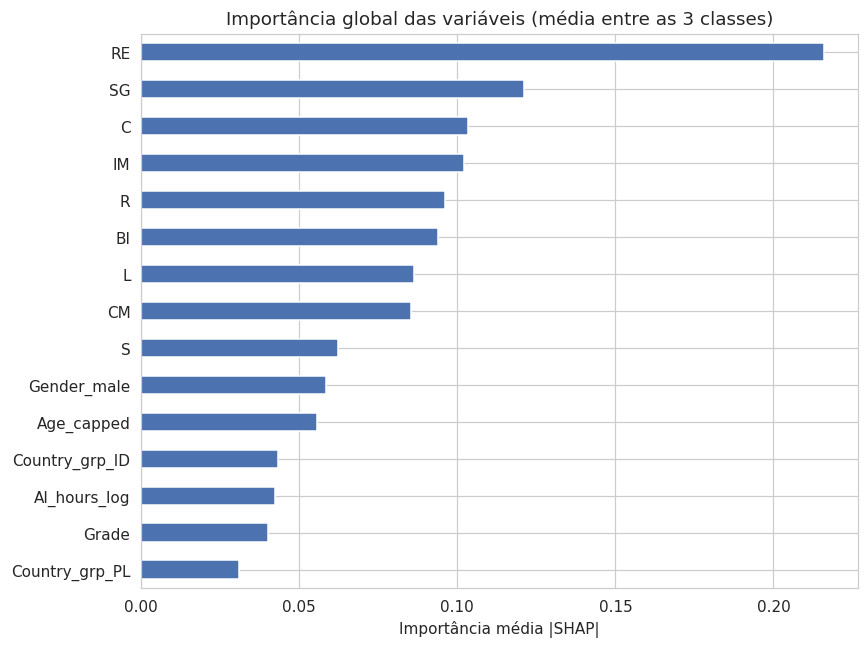

In [44]:
# Gráfico de importância global (barras)
fig, ax = plt.subplots(figsize=(8, 6))
importance_global.head(15).sort_values().plot(kind='barh', ax=ax, color='#4c72b0')
ax.set_xlabel('Importância média |SHAP|')
ax.set_title('Importância global das variáveis (média entre as 3 classes)')
plt.tight_layout()
plt.show()


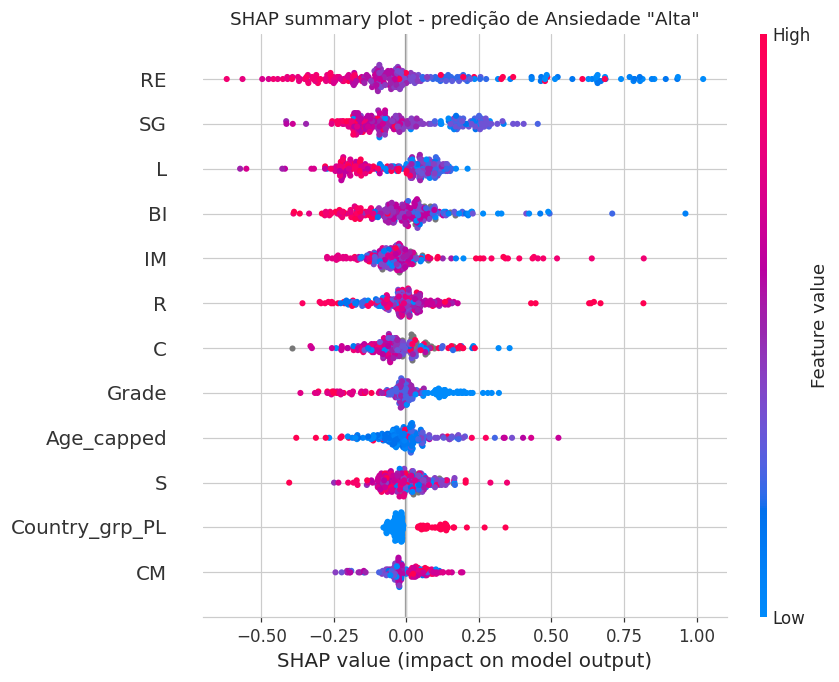

In [45]:
# Summary plot para a classe "Alta" (identifique o índice correto em le.classes_)
classe_alvo = 'Alta'
idx_classe = list(le.classes_).index(classe_alvo)

shap.summary_plot(
    shap_values[:, :, idx_classe],
    X_test_nat,
    feature_names=feature_cols,
    max_display=12,
    show=False
)
plt.title(f'SHAP summary plot - predição de Ansiedade "{classe_alvo}"')
plt.tight_layout()
plt.show()


### 13.1 Interpretabilidade do Random Forest (SHAP TreeExplainer)

O Random Forest também é um modelo baseado em árvore, portanto utiliza o mesmo `TreeExplainer` (rápido e exato) aplicado ao XGBoost. Comparar a importância de variáveis entre os dois algoritmos de natureza semelhante, mas com lógicas de construção distintas (bagging vs. boosting), fortalece a robustez das conclusões sobre quais construtos mais influenciam a Ansiedade.

In [46]:
explainer_rf = shap.TreeExplainer(models['Random Forest'])
shap_values_rf = explainer_rf.shap_values(X_test_imp)

mean_abs_shap_rf = np.abs(shap_values_rf).mean(axis=(0, 2))
importance_global_rf = pd.Series(mean_abs_shap_rf, index=feature_cols).sort_values(ascending=False)

print("=== Ranking de importância global das variáveis - Random Forest ===")
importance_global_rf.head(15)


=== Ranking de importância global das variáveis - Random Forest ===


,0
RE,0.028144
SG,0.022429
L,0.013356
C,0.011955
BI,0.009839
CM,0.009339
Gender_male,0.009247
R,0.008145
Gender_female,0.007545
IM,0.007173


In [47]:
# Comparação lado a lado do ranking de importância entre os três modelos com SHAP calculado
comparacao_importancia = pd.DataFrame({
    'XGBoost': importance_global,
    'Random Forest': importance_global_rf,
}).fillna(0)

# normaliza cada coluna (0 a 1) para facilitar a comparação visual entre escalas diferentes
comparacao_importancia_norm = comparacao_importancia / comparacao_importancia.max()
comparacao_importancia_norm.sort_values('XGBoost', ascending=False).head(10)


,XGBoost,Random Forest
RE,1.000000,1.000000
SG,0.560995,0.796944
C,0.479095,0.424772
IM,0.472896,0.254863
R,0.444374,0.289405
BI,0.434999,0.349581
L,0.399724,0.474562
CM,0.395937,0.331810
S,0.288460,0.223402
Gender_male,0.271288,0.328544


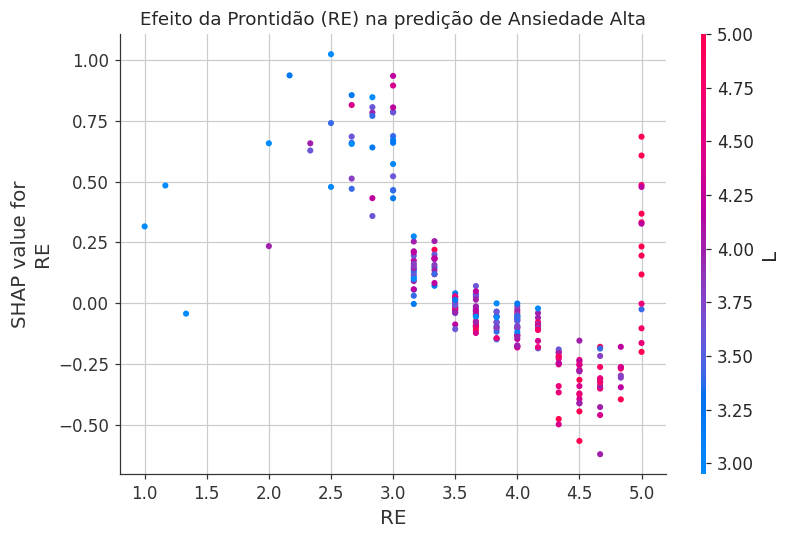

In [48]:
# Dependence plot: como o valor de um construto específico (ex.: RE - Prontidão)
# se relaciona com seu impacto na predição de Ansiedade Alta
shap.dependence_plot(
    'RE',
    shap_values[:, :, idx_classe],
    X_test_nat,
    feature_names=feature_cols,
    show=False
)
plt.title('Efeito da Prontidão (RE) na predição de Ansiedade Alta')
plt.tight_layout()
plt.show()


### Interpretabilidade do SVM (SHAP KernelExplainer)

Diferente dos modelos baseados em árvore (Random Forest, XGBoost), que utilizam o `TreeExplainer` (rápido e exato), o SVM exige o `KernelExplainer`, um método agnóstico ao modelo baseado em amostragem — e, por isso, significativamente mais lento (Lundberg; Lee, 2017). Por esse motivo, a análise abaixo utiliza uma amostra reduzida do conjunto de treino como *background* e uma amostra do conjunto de teste, prática recomendada na documentação oficial do SHAP para modelos não baseados em árvore.

In [49]:
# KernelExplainer para o SVM (mais lento -> usar amostras reduzidas)
background = shap.sample(X_train_imp, 50, random_state=RANDOM_STATE)
X_test_sample_svm = X_test_imp.sample(min(100, len(X_test_imp)), random_state=RANDOM_STATE)

explainer_svm = shap.KernelExplainer(models['SVM'].predict_proba, background)
shap_values_svm = explainer_svm.shap_values(X_test_sample_svm, nsamples=100)

print("Shape dos valores SHAP (SVM):", np.array(shap_values_svm).shape)


  0%|          | 0/100 [00:00<?, ?it/s]

Shape dos valores SHAP (SVM): (100, 32, 3)


In [50]:
# Importância global de variáveis segundo o SVM (para comparar com o ranking do XGBoost)
mean_abs_shap_svm = np.abs(shap_values_svm).mean(axis=(0, 2))
importance_global_svm = pd.Series(mean_abs_shap_svm, index=feature_cols).sort_values(ascending=False)

print("=== Ranking de importância global das variáveis - SVM ===")
importance_global_svm.head(15)


=== Ranking de importância global das variáveis - SVM ===


,0
RE,0.031112
C,0.012950
SG,0.012788
R,0.010209
CM,0.009951
L,0.008153
Grade,0.007015
Country_grp_SK,0.004076
Gender_male,0.003890
IM,0.003579


**Comparação entre algoritmos:** compare `importance_global` (XGBoost) com `importance_global_svm` (SVM) para verificar se o ranking das variáveis mais importantes é consistente entre modelos de naturezas distintas (baseado em árvore vs. baseado em margem). Alta concordância entre os dois rankings fortalece a robustez das conclusões sobre quais construtos mais influenciam a Ansiedade, independentemente do algoritmo utilizado.

**Interpretação esperada:** espera-se que construtos como Prontidão (RE), Confiança (C) e Satisfação (S) apresentem maior importância e efeito negativo sobre a predição de Ansiedade Alta (valores altos do construto empurrando a predição para "Baixa"), fornecendo suporte empírico à Hipótese H1. As flags de ausência estrutural (`IM_na`, `S_na`, `C_na`, `BI_na`) também devem ser observadas: importância relevante dessas variáveis indicaria que a mera falta de experiência prévia com IA já é, por si só, preditora de maior ansiedade.

---
# Parte II — Aprendizado Não Supervisionado: Descoberta de Perfis de Estudantes

Esta segunda parte do notebook responde à **Pergunta de Pesquisa 2**: é possível identificar perfis distintos de estudantes a partir da combinação dos dez construtos psicométricos, sem uso prévio de rótulos ou categorias pré-definidas? Diferente da Parte I, que excluiu o construto de Ansiedade (A) das variáveis preditoras por ele ser a base da variável-alvo supervisionada, aqui **todos os dez construtos são utilizados simultaneamente**, incluindo A, pois o objetivo não é prever a ansiedade a partir de outras variáveis, mas descobrir como todos os construtos se organizam conjuntamente nos estudantes.

## 14. Preparação dos dados para clusterização

Como 59 estudantes responderam ao instrumento em mais de uma onda de coleta (2022 e 2024), a clusterização é realizada em **nível de estudante** (não de registro), agregando os construtos pela média das ondas de cada estudante, para que o mesmo indivíduo não seja contabilizado duas vezes e não influencie desproporcionalmente a formação dos clusters.

In [51]:
construct_cols = ['L', 'RE', 'R', 'SG', 'CM', 'A', 'IM', 'S', 'C', 'BI']

# Agregação em nível de estudante (média das ondas, para os 59 casos longitudinais)
person = scores.groupby('user_id')[construct_cols].mean().reset_index()
print("N de estudantes únicos:", len(person))
print("\nValores ausentes por construto (antes da imputação):")
print(person[construct_cols].isna().sum())


N de estudantes únicos: 1146

Valores ausentes por construto (antes da imputação):
L       0
RE      0
R       0
SG      0
CM      0
A       0
IM    171
S     178
C     257
BI     99
dtype: int64


In [52]:
# Imputação pela mediana nos construtos com missing estrutural (mesma estratégia da Parte I)
for col in ['IM', 'S', 'C', 'BI']:
    person[col] = person[col].fillna(person[col].median())

# Padronização (obrigatória para o K-Means, que é sensível à escala das variáveis)
scaler_cluster = StandardScaler()
X_cluster = scaler_cluster.fit_transform(person[construct_cols])

print("Shape da matriz de clusterização:", X_cluster.shape)


Shape da matriz de clusterização: (1146, 10)


## 15. Determinação do número ideal de clusters (Coeficiente de Silhueta)

O K-Means exige a definição prévia do número de clusters (*k*). Para evitar uma escolha arbitrária, testamos k de 2 a 8 e avaliamos cada solução pelo Coeficiente de Silhueta (Rousseeuw, 1987), que mede o quão similar cada estudante é ao seu próprio cluster em comparação aos clusters vizinhos (valores mais próximos de 1 indicam melhor separação).

In [53]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sil_scores = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_cluster)
    sil_scores[k] = silhouette_score(X_cluster, labels)
    print(f"k={k}: Coeficiente de Silhueta = {sil_scores[k]:.4f}")

best_k_silhouette = max(sil_scores, key=sil_scores.get)
print(f"\nMelhor k pelo critério estritamente estatístico: {best_k_silhouette}")


k=2: Coeficiente de Silhueta = 0.2426
k=3: Coeficiente de Silhueta = 0.2026
k=4: Coeficiente de Silhueta = 0.1259
k=5: Coeficiente de Silhueta = 0.1221
k=6: Coeficiente de Silhueta = 0.1177
k=7: Coeficiente de Silhueta = 0.1166
k=8: Coeficiente de Silhueta = 0.1098

Melhor k pelo critério estritamente estatístico: 2


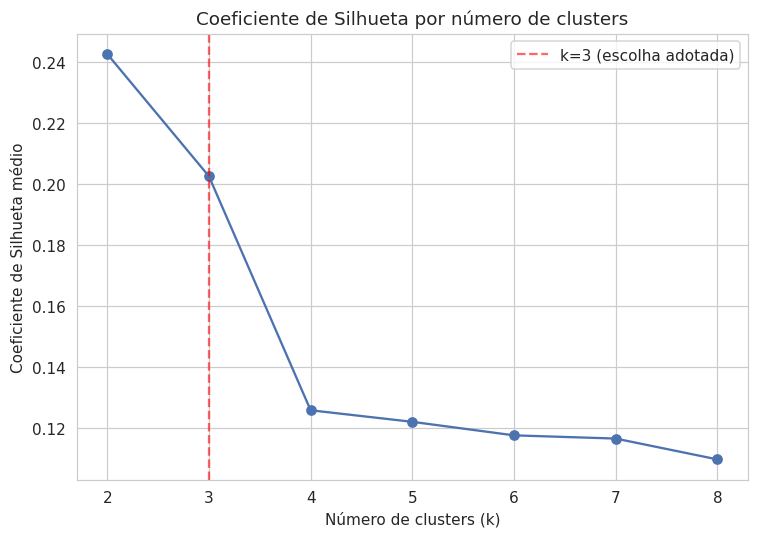

In [54]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o', color='#4c72b0')
ax.set_xlabel('Número de clusters (k)')
ax.set_ylabel('Coeficiente de Silhueta médio')
ax.set_title('Coeficiente de Silhueta por número de clusters')
ax.axvline(x=3, color='red', linestyle='--', alpha=0.6, label='k=3 (escolha adotada)')
ax.legend()
plt.tight_layout()
plt.show()


**Decisão metodológica sobre k:** o critério puramente estatístico aponta k=2 como o de maior silhueta (0,243), seguido de perto por k=3 (0,203). Optou-se por adotar **k=3** como solução final, por dois motivos: (i) a diferença de silhueta entre k=2 e k=3 é pequena, e ambos os valores situam-se na faixa que Kaufman e Rousseeuw (1990) associam a ausência de estrutura de agrupamento substancial (silhueta ≤ 0,25), de modo que os clusters devem ser interpretados como uma partição útil de um contínuo de atitudes, e não como grupos naturalmente separados; e (ii) a solução com 3 clusters é consideravelmente mais interpretável e acionável pedagogicamente, isolando especificamente um subgrupo de alta ansiedade que a solução de 2 clusters mistura com o grupo intermediário — além de ser consistente com o número de perfis relatado em estudos anteriores de alfabetização em IA (ver seção de Trabalhos Relacionados). Essa é uma decisão metodológica explícita de priorizar interpretabilidade sobre a otimização estatística marginal, e deve ser reportada como tal no artigo.

## 16. Caracterização dos perfis (k=3)

In [55]:
km_final = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
person['cluster'] = km_final.fit_predict(X_cluster)

profile_means = person.groupby('cluster')[construct_cols].mean()
print(profile_means.round(2))
print()
print(person['cluster'].value_counts())


            L    RE     R    SG    CM     A    IM     S     C    BI
cluster                                                            
0        3.79  3.63  3.58  3.64  3.42  2.61  3.44  3.50  3.45  3.67
1        4.43  4.34  4.35  4.18  4.33  2.39  4.06  4.06  3.97  4.30
2        3.31  2.81  2.73  2.90  2.31  3.12  2.42  2.35  2.95  2.47

cluster
0    567
1    453
2    126
Name: count, dtype: int64


In [56]:
# Nomeação dos perfis com base no nível de Ansiedade (ordenado do menor para o maior)
order_by_anxiety = profile_means['A'].sort_values().index
rename_map = {
    order_by_anxiety[0]: 'Confiantes e Engajados',
    order_by_anxiety[1]: 'Moderados',
    order_by_anxiety[2]: 'Ansiosos e Resistentes',
}
person['perfil'] = person['cluster'].map(rename_map)

profile_means_named = person.groupby('perfil')[construct_cols].mean().loc[list(rename_map.values())]
print(person['perfil'].value_counts())


perfil
Moderados                 567
Confiantes e Engajados    453
Ansiosos e Resistentes    126
Name: count, dtype: int64


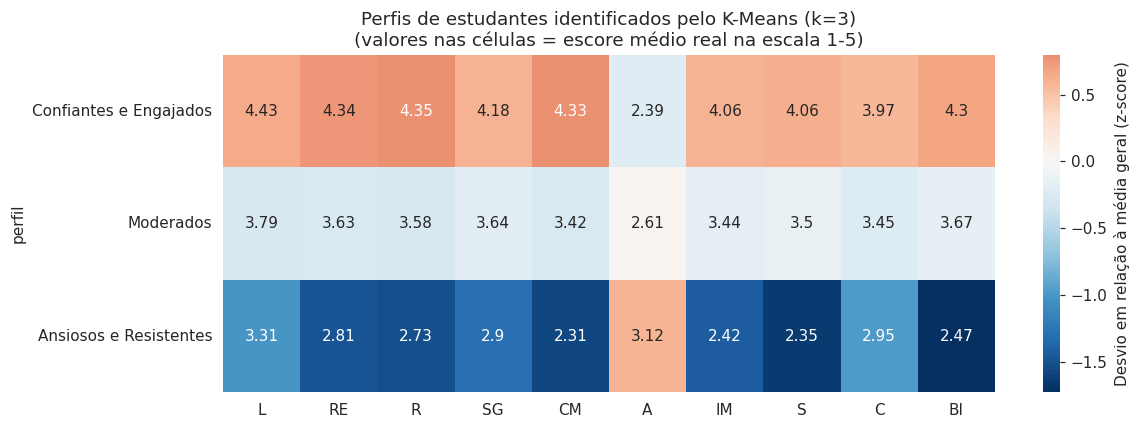

In [57]:
# Heatmap dos perfis (z-score para comparar os construtos na mesma escala; valores anotados = escore médio real)
profile_z = (profile_means_named - person[construct_cols].mean()) / person[construct_cols].std()

fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(profile_z, annot=profile_means_named.round(2), fmt='', cmap='RdBu_r', center=0, ax=ax,
            cbar_kws={'label': 'Desvio em relação à média geral (z-score)'})
ax.set_title('Perfis de estudantes identificados pelo K-Means (k=3)\n(valores nas células = escore médio real na escala 1-5)')
plt.tight_layout()
plt.show()


**Interpretação dos perfis:**
- **Confiantes e Engajados**: escores elevados em todos os construtos positivos (L, RE, R, SG, CM, IM, S, C, BI) e o menor nível de Ansiedade (A = 2,39) entre os três grupos.
- **Moderados**: escores intermediários em praticamente todos os construtos, incluindo Ansiedade (A = 2,61).
- **Ansiosos e Resistentes**: o único grupo com inversão do padrão — menores escores em todos os construtos positivos **e o maior nível de Ansiedade** (A = 3,12), caracterizando o perfil de maior vulnerabilidade e, potencialmente, de maior necessidade de suporte pedagógico direcionado.

## 17. Distribuição dos perfis por país e validação cruzada com a classe supervisionada de Ansiedade

Esta etapa conecta a abordagem não supervisionada com os dois achados anteriores do estudo: (i) a variação por país já observada na EDA, e (ii) a classe de Ansiedade (Baixa/Média/Alta) definida na Parte I, permitindo verificar se as duas abordagens — supervisionada e não supervisionada — convergem para conclusões consistentes.

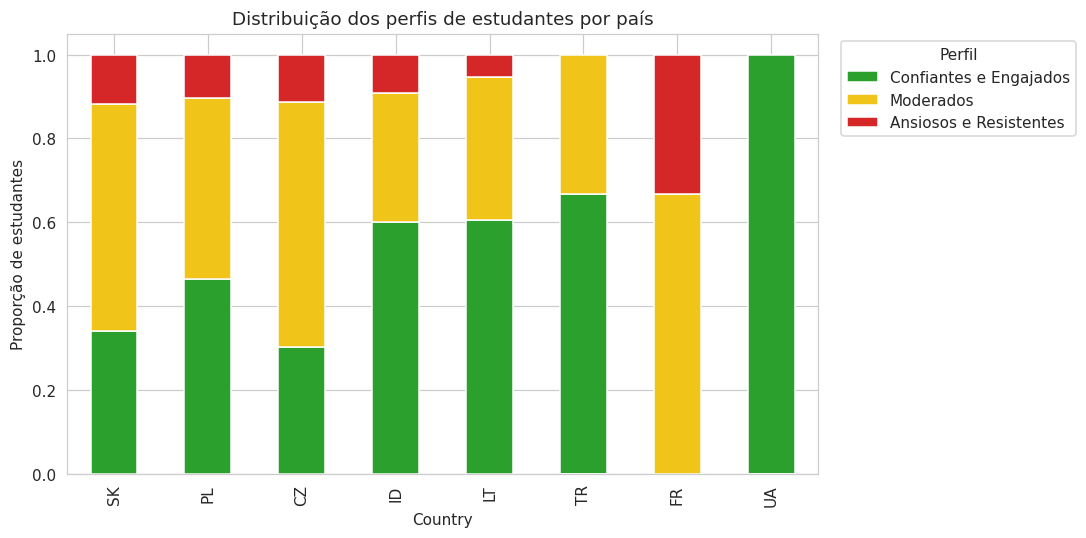

In [58]:
# Distribuição dos perfis por país
scores_country = scores.groupby('user_id')['Country'].first().reset_index()
person = person.merge(scores_country, on='user_id')

ct_country = pd.crosstab(person['Country'], person['perfil'], normalize='index')[list(rename_map.values())]
ct_country = ct_country.loc[person['Country'].value_counts().index]

fig, ax = plt.subplots(figsize=(10, 5))
ct_country.plot(kind='bar', stacked=True, ax=ax, color=['#2ca02c', '#f0c419', '#d62728'])
ax.set_ylabel('Proporção de estudantes')
ax.set_title('Distribuição dos perfis de estudantes por país')
ax.legend(title='Perfil', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


**Nota de cautela:** Turquia, França e Ucrânia têm amostras muito pequenas (N ≤ 6), de modo que sua distribuição 100% concentrada em um único perfil não deve ser interpretada como representativa, replicando a mesma limitação já discutida na EDA e na avaliação de generalização por subgrupo (Seção 12.3).

In [59]:
# Validação cruzada: perfis não supervisionados (K-Means) vs. classe supervisionada de Ansiedade (Parte I)
anx_class_person = scores.groupby('user_id')['Anxiety_class'].agg(lambda x: x.mode().iloc[0]).reset_index()
person = person.merge(anx_class_person, on='user_id')

ct_anxiety = pd.crosstab(person['perfil'], person['Anxiety_class'], normalize='index').round(3)
ct_anxiety = ct_anxiety.loc[list(rename_map.values())]
ct_anxiety


Anxiety_class,Alta,Baixa,Média
perfil,,,
Confiantes e Engajados,0.212,0.450,0.338
Moderados,0.287,0.293,0.420
Ansiosos e Resistentes,0.524,0.206,0.270


**Convergência com a classe supervisionada de Ansiedade:** 52% dos estudantes do perfil "Ansiosos e Resistentes" pertencem à classe "Alta", contra 21% no perfil "Confiantes e Engajados". **Atenção:** como o construto A entra na clusterização e também origina a classe supervisionada, essa convergência é em parte esperada por construção. A célula seguinte repete a clusterização **sem o construto A**, que é a verificação não circular.

In [60]:
# Verificação não circular: clusterização SEM o construto Ansiedade (A)
from sklearn.metrics import adjusted_rand_score
from scipy.stats import kruskal

cols9 = [c for c in construct_cols if c != 'A']
X9 = StandardScaler().fit_transform(person[cols9])
person['cluster_sem_A'] = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit_predict(X9)

print("ARI entre solução com A e sem A:", round(adjusted_rand_score(person['cluster'], person['cluster_sem_A']), 3))
print(person.groupby('cluster_sem_A')[construct_cols].mean().round(2))
print()
print(pd.crosstab(person['cluster_sem_A'], person['Anxiety_class'], normalize='index').round(2))
print("\nKruskal-Wallis (A entre clusters):", kruskal(*[g['A'].values for _, g in person.groupby('cluster_sem_A')]))


ARI entre solução com A e sem A: 0.897
                  L    RE     R    SG    CM     A    IM     S     C    BI
cluster_sem_A                                                            
0              3.35  2.90  2.77  2.99  2.35  2.97  2.47  2.42  2.98  2.54
1              4.43  4.35  4.36  4.19  4.36  2.42  4.07  4.09  3.98  4.32
2              3.82  3.66  3.61  3.65  3.46  2.60  3.47  3.52  3.47  3.70

Anxiety_class  Alta  Baixa  Média
cluster_sem_A                    
0              0.47   0.27   0.26
1              0.22   0.43   0.34
2              0.28   0.30   0.42

Kruskal-Wallis (A entre clusters): KruskalResult(statistic=np.float64(40.68691829591597), pvalue=np.float64(1.4620019410414308e-09))


Sem o construto A, os agrupamentos permanecem praticamente idênticos (ARI ≈ 0,90) e a Ansiedade, que não participou da formação dos clusters, continua diferindo significativamente entre eles (Kruskal-Wallis, p < 0,001). Esse é o resultado que sustenta a convergência entre as duas abordagens.

## 18. Exportação dos perfis identificados

In [61]:
person.to_csv('perfis_estudantes.csv', index=False)
print("Arquivo 'perfis_estudantes.csv' exportado com sucesso.")

# No Colab, baixe o arquivo para seu computador:
# from google.colab import files
# files.download('perfis_estudantes.csv')


Arquivo 'perfis_estudantes.csv' exportado com sucesso.


---
## Síntese final do notebook

Com a conclusão desta Parte II, as duas perguntas de pesquisa do estudo foram respondidas metodologicamente:

1. **Pergunta 1 (supervisionada):** os construtos Prontidão (RE), Bem Social (SG) e Confiança (C) emergiram como os principais preditores da Ansiedade frente à IA, segundo a análise SHAP sobre o XGBoost e o Random Forest, fornecendo suporte à Hipótese H1.
2. **Pergunta 2 (não supervisionada):** três perfis latentes de estudantes foram identificados (Confiantes e Engajados, Moderados, Ansiosos e Resistentes), com validação cruzada confirmando forte convergência com a classe de Ansiedade definida de forma independente na Parte I.

Os resultados de ambas as frentes — incluindo a limitação de generalização identificada na Seção 12.3 (desempenho reduzido em subgrupos minoritários) — devem ser discutidos conjuntamente na seção de Discussão do artigo, à luz da literatura revisada.